In [1]:

# ============================================================
# STEP 1: INSTALL REQUIRED LIBRARIES
# ============================================================

!pip -q install \
    datasets \
    sentence-transformers \
    chromadb \
    transformers \
    nltk \
    pandas \
    numpy \
    scikit-learn \
    matplotlib \
    tqdm

print("=" * 60)
print("STEP 1: ENVIRONMENT SETUP")
print("=" * 60)
print("PASS: Required libraries installed successfully.")
print("=" * 60)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requi

In [2]:

# ============================================================
# STEP 2: FIX DEPENDENCIES AND LOAD ARXIV DATASET
# ============================================================

%pip -q install "python-dateutil>=2.9.0.post0,<3" \
                "oauthlib>=3.2.0,<4" \
                "opentelemetry-api>=1.39,<=1.42.1" \
                "opentelemetry-sdk>=1.39,<=1.42.1"

from datasets import load_dataset
import pandas as pd

print("=" * 60)
print("STEP 2: ARXIV DATASET LOADING")
print("=" * 60)

DATASET_NAME = "ccdv/arxiv-summarization"
SUBSET = "document"
NUM_DOCUMENTS = 100

# Load the first 100 training documents
dataset = load_dataset(
    DATASET_NAME,
    SUBSET,
    split="train[:100]"
)

# Convert dataset to DataFrame
df = dataset.to_pandas()

print(f"Dataset       : {DATASET_NAME}")
print(f"Subset        : {SUBSET}")
print(f"Split         : train")
print(f"Documents     : {len(df)}")
print(f"Columns       : {list(df.columns)}")

# Inspect first document
print("\nFIRST DOCUMENT PREVIEW")
print("-" * 60)

for column in df.columns:
    value = str(df.iloc[0][column])
    print(f"{column}: {value[:300]}")

# Verify dataset
assert len(df) == 100, "Expected exactly 100 documents"

print("\n" + "=" * 60)
print("PASS: First 100 documents loaded successfully.")
print("=" * 60)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
kubernetes 37.0.2 requires oauthlib>=4.0.0, but you have oauthlib 3.3.1 which is incompatible.
kubernetes 37.0.2 requires python-dateutil>=3.0.0, but you have python-dateutil 2.9.0.post0 which is incompatible.
opentelemetry-exporter-otlp-proto-grpc 1.45.2 requires opentelemetry-sdk~=1.45.2, but you have opentelemetry-sdk 1.42.1 which is incompatible.
opentelemetry-exporter-otlp-common 0.66b2 requires opentelemetry-sdk~=1.45.2, but you have opentelemetry-sdk 1.42.1 which is incompatible.
STEP 2: ARXIV DATASET LOADING


README.md:   0%|          | 0.00/3.96k [00:00<?, ?B/s]

document/train-00000-of-00015.parquet: reconstructing file:   0%|          |  0.00B /  227MB            

document/train-00000-of-00015.parquet: downloading bytes:           |  0.00B            

document/train-00001-of-00015.parquet: reconstructing file:   0%|          |  0.00B /  226MB            

document/train-00001-of-00015.parquet: downloading bytes:           |  0.00B            

... (30 outputs left out)

Generating train split:   0%|          | 0/203037 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/6436 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/6440 [00:00<?, ? examples/s]

Dataset       : ccdv/arxiv-summarization
Subset        : document
Split         : train
Documents     : 100
Columns       : ['article', 'abstract']

FIRST DOCUMENT PREVIEW
------------------------------------------------------------
article: additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fu
abstract: additive models play an important role in semiparametric statistics . 
 this paper gives learning rates for regularized kernel based methods for additive models . 
 these learning rates compare favourably in particular in high dimensions to recent results on optimal learning rates for purely nonpara

PASS: First 100 documents loaded successfully.


In [3]:

# ============================================================
# STEP 3: PREPROCESS ARXIV DOCUMENTS
# ============================================================

import re
import pandas as pd

print("=" * 60)
print("STEP 3: DOCUMENT PREPROCESSING")
print("=" * 60)

# 1. Create a working copy
processed_df = df.copy()

# 2. Clean text
def clean_text(text):
    if not isinstance(text, str):
        return ""

    text = re.sub(r"\s+", " ", text)
    text = text.strip()

    return text

# 3. Clean article and abstract
processed_df["article"] = processed_df["article"].apply(
    clean_text
)

processed_df["abstract"] = processed_df["abstract"].apply(
    clean_text
)

# 4. Assign unique document IDs
processed_df["doc_id"] = [
    f"DOC_{i:03d}"
    for i in range(1, len(processed_df) + 1)
]

# 5. Remove empty articles
processed_df = processed_df[
    processed_df["article"].str.len() > 0
].copy()

processed_df.reset_index(drop=True, inplace=True)

# 6. Calculate document statistics
processed_df["word_count"] = (
    processed_df["article"].str.split().str.len()
)

print(f"Original documents   : {len(df)}")
print(f"Processed documents  : {len(processed_df)}")
print(f"Empty articles removed: {len(df) - len(processed_df)}")

print("\nDOCUMENT STATISTICS")
print("-" * 60)

print(f"Average words : {processed_df['word_count'].mean():.2f}")
print(f"Minimum words : {processed_df['word_count'].min()}")
print(f"Maximum words : {processed_df['word_count'].max()}")

print("\nFIRST DOCUMENT PREVIEW")
print("-" * 60)

print("Document ID :", processed_df.iloc[0]["doc_id"])
print("Word Count  :", processed_df.iloc[0]["word_count"])
print("Article     :", processed_df.iloc[0]["article"][:400])

# 7. Verification
assert len(processed_df) == 100, (
    "Expected 100 non-empty documents"
)

assert processed_df["doc_id"].is_unique, (
    "Document IDs must be unique"
)

assert processed_df["article"].str.len().gt(0).all(), (
    "Empty articles detected"
)

print("\n" + "=" * 60)
print("PASS: Document preprocessing completed.")
print("=" * 60)


STEP 3: DOCUMENT PREPROCESSING
Original documents   : 100
Processed documents  : 100
Empty articles removed: 0

DOCUMENT STATISTICS
------------------------------------------------------------
Average words : 6516.53
Minimum words : 604
Maximum words : 33095

FIRST DOCUMENT PREVIEW
------------------------------------------------------------
Document ID : DOC_001
Word Count  : 4467
Article     : additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models . it is well - known that good estimators in additive models are in general

PASS: Document preprocessing completed.


In [4]:

# ============================================================
# STEP 4: FIXED-SIZE TOKEN CHUNKING
# ============================================================

from transformers import AutoTokenizer
import pandas as pd

print("=" * 60)
print("STEP 4: FIXED-SIZE TOKEN CHUNKING")
print("=" * 60)

# 1. Configuration
MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

CHUNK_SIZE = 500
CHUNK_OVERLAP = 50
STEP_SIZE = CHUNK_SIZE - CHUNK_OVERLAP

# 2. Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# 3. Fixed-size chunking function
def fixed_size_chunking(text, chunk_size=500, overlap=50):

    token_ids = tokenizer.encode(
        text,
        add_special_tokens=False
    )

    chunks = []
    step = chunk_size - overlap

    for start in range(0, len(token_ids), step):

        chunk_ids = token_ids[start:start + chunk_size]

        if not chunk_ids:
            continue

        chunk_text = tokenizer.decode(
            chunk_ids,
            skip_special_tokens=True
        )

        chunks.append({
            "text": chunk_text,
            "token_count": len(chunk_ids)
        })

        if start + chunk_size >= len(token_ids):
            break

    return chunks

# 4. Apply chunking to all documents
fixed_chunks = []

for _, row in processed_df.iterrows():

    doc_chunks = fixed_size_chunking(row["article"])

    for chunk_index, chunk in enumerate(doc_chunks):

        fixed_chunks.append({
            "chunk_id": f"{row['doc_id']}_FIX_{chunk_index:04d}",
            "doc_id": row["doc_id"],
            "chunk_index": chunk_index,
            "text": chunk["text"],
            "token_count": chunk["token_count"],
            "strategy": "fixed"
        })

# 5. Convert to DataFrame
fixed_chunks_df = pd.DataFrame(fixed_chunks)

# 6. Statistics
print(f"Documents processed : {len(processed_df)}")
print(f"Total chunks        : {len(fixed_chunks_df)}")
print(f"Chunk size          : {CHUNK_SIZE}")
print(f"Chunk overlap       : {CHUNK_OVERLAP}")

print("\nCHUNK STATISTICS")
print("-" * 60)

print(f"Average tokens : {fixed_chunks_df['token_count'].mean():.2f}")
print(f"Minimum tokens : {fixed_chunks_df['token_count'].min()}")
print(f"Maximum tokens : {fixed_chunks_df['token_count'].max()}")

print("\nFIRST CHUNK PREVIEW")
print("-" * 60)

print("Chunk ID :", fixed_chunks_df.iloc[0]["chunk_id"])
print("Doc ID   :", fixed_chunks_df.iloc[0]["doc_id"])
print("Tokens   :", fixed_chunks_df.iloc[0]["token_count"])
print("Text     :", fixed_chunks_df.iloc[0]["text"][:400])

# 7. Verification
assert len(fixed_chunks_df) > 0
assert fixed_chunks_df["chunk_id"].is_unique
assert fixed_chunks_df["token_count"].max() <= CHUNK_SIZE
assert fixed_chunks_df["doc_id"].nunique() == 100

print("\n" + "=" * 60)
print("PASS: Fixed-size chunking completed.")
print("=" * 60)


STEP 4: FIXED-SIZE TOKEN CHUNKING


config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (7298 > 512). Running this sequence through the model will result in indexing errors


Documents processed : 100
Total chunks        : 2310
Chunk size          : 500
Chunk overlap       : 50

CHUNK STATISTICS
------------------------------------------------------------
Average tokens : 489.81
Minimum tokens : 58
Maximum tokens : 500

FIRST CHUNK PREVIEW
------------------------------------------------------------
Chunk ID : DOC_001_FIX_0000
Doc ID   : DOC_001
Tokens   : 500
Text     : additive models @ xcite provide an important family of models for semiparametric regression or classification. some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models. it is well - known that good estimators in additive models are in general 

PASS: Fixed-size chunking completed.


In [5]:

# ============================================================
# STEP 5: SENTENCE-AWARE CHUNKING + FAIR COMPARISON
# ============================================================

import re
import pandas as pd

print("=" * 60)
print("STEP 5: SENTENCE-AWARE CHUNKING")
print("=" * 60)

# 1. Shared configuration
CHUNK_SIZE = 240
CHUNK_OVERLAP = 40

# 2. Rebuild fixed chunks using the updated token budget
fixed_chunks = []

for _, row in processed_df.iterrows():

    doc_chunks = fixed_size_chunking(
        row["article"],
        chunk_size=CHUNK_SIZE,
        overlap=CHUNK_OVERLAP
    )

    for i, chunk in enumerate(doc_chunks):
        fixed_chunks.append({
            "chunk_id": f"{row['doc_id']}_FIX_{i:04d}",
            "doc_id": row["doc_id"],
            "chunk_index": i,
            "text": chunk["text"],
            "token_count": chunk["token_count"],
            "strategy": "fixed"
        })

fixed_chunks_df = pd.DataFrame(fixed_chunks)

# 3. Sentence-aware chunking
def sentence_aware_chunking(text, chunk_size=240, overlap=40):

    # Split text at sentence boundaries
    sentences = re.split(r'(?<=[.!?])\s+', text)

    # Convert sentences into token IDs
    units = []

    for sentence in sentences:
        ids = tokenizer.encode(
            sentence,
            add_special_tokens=False,
            verbose=False
        )

        # Split unusually long sentences
        for start in range(0, len(ids), chunk_size):
            units.append(ids[start:start + chunk_size])

    chunks = []
    current = []

    for unit in units:

        if current and len(current) + len(unit) > chunk_size:

            chunks.append(current.copy())

            # Retain trailing token overlap
            current = current[-overlap:] if overlap else []

            # Avoid overlap preventing the next unit from fitting
            if len(current) + len(unit) > chunk_size:
                current = []

        current.extend(unit)

    if current:
        chunks.append(current)

    return [
        {
            "text": tokenizer.decode(
                ids,
                skip_special_tokens=True
            ),
            "token_count": len(ids)
        }
        for ids in chunks
    ]

# 4. Apply sentence-aware chunking
sentence_chunks = []

for _, row in processed_df.iterrows():

    doc_chunks = sentence_aware_chunking(
        row["article"],
        chunk_size=CHUNK_SIZE,
        overlap=CHUNK_OVERLAP
    )

    for i, chunk in enumerate(doc_chunks):
        sentence_chunks.append({
            "chunk_id": f"{row['doc_id']}_SENT_{i:04d}",
            "doc_id": row["doc_id"],
            "chunk_index": i,
            "text": chunk["text"],
            "token_count": chunk["token_count"],
            "strategy": "sentence"
        })

sentence_chunks_df = pd.DataFrame(sentence_chunks)

# 5. Comparison
comparison_df = pd.DataFrame({
    "Strategy": ["Fixed-size", "Sentence-aware"],
    "Total Chunks": [
        len(fixed_chunks_df),
        len(sentence_chunks_df)
    ],
    "Average Tokens": [
        round(fixed_chunks_df["token_count"].mean(), 2),
        round(sentence_chunks_df["token_count"].mean(), 2)
    ],
    "Minimum Tokens": [
        fixed_chunks_df["token_count"].min(),
        sentence_chunks_df["token_count"].min()
    ],
    "Maximum Tokens": [
        fixed_chunks_df["token_count"].max(),
        sentence_chunks_df["token_count"].max()
    ]
})

print("\nCHUNKING COMPARISON")
print("-" * 60)
print(comparison_df.to_string(index=False))

# 6. Verification
for name, chunks_df in [
    ("Fixed", fixed_chunks_df),
    ("Sentence-aware", sentence_chunks_df)
]:
    assert chunks_df["chunk_id"].is_unique
    assert chunks_df["doc_id"].nunique() == 100
    assert chunks_df["token_count"].max() <= CHUNK_SIZE
    assert chunks_df["text"].str.len().gt(0).all()

    print(f"PASS: {name} chunking verified.")

print("\n" + "=" * 60)
print("PASS: Both chunking strategies completed.")
print("=" * 60)


STEP 5: SENTENCE-AWARE CHUNKING

CHUNKING COMPARISON
------------------------------------------------------------
      Strategy  Total Chunks  Average Tokens  Minimum Tokens  Maximum Tokens
    Fixed-size          5131          238.20              42             240
Sentence-aware          5811          212.47              44             240
PASS: Fixed chunking verified.
PASS: Sentence-aware chunking verified.

PASS: Both chunking strategies completed.


In [6]:

# ============================================================
# STEP 6: GENERATE EMBEDDINGS USING GPU
# ============================================================

import torch
import numpy as np
import time
from sentence_transformers import SentenceTransformer

print("=" * 60)
print("STEP 6: EMBEDDING GENERATION")
print("=" * 60)

# 1. Detect device
device = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Device             : {device}")

if device == "cuda":
    print(f"GPU                : {torch.cuda.get_device_name(0)}")

# 2. Load embedding model
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

model = SentenceTransformer(
    EMBEDDING_MODEL,
    device=device
)

print(f"Embedding model    : {EMBEDDING_MODEL}")
print(f"Embedding dimension: {model.get_sentence_embedding_dimension()}")
print(f"Max sequence length: {model.max_seq_length}")

# 3. Prepare chunk texts
fixed_texts = fixed_chunks_df["text"].tolist()
sentence_texts = sentence_chunks_df["text"].tolist()

# 4. Generate fixed-size embeddings
print("\nGENERATING FIXED-SIZE EMBEDDINGS")
print("-" * 60)

start = time.time()

fixed_embeddings = model.encode(
    fixed_texts,
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

fixed_time = time.time() - start

# 5. Generate sentence-aware embeddings
print("\nGENERATING SENTENCE-AWARE EMBEDDINGS")
print("-" * 60)

start = time.time()

sentence_embeddings = model.encode(
    sentence_texts,
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

sentence_time = time.time() - start

# 6. Verify embeddings
assert fixed_embeddings.shape == (
    len(fixed_chunks_df), 384
)

assert sentence_embeddings.shape == (
    len(sentence_chunks_df), 384
)

assert np.isfinite(fixed_embeddings).all()
assert np.isfinite(sentence_embeddings).all()

print("\nEMBEDDING SUMMARY")
print("-" * 60)

print(f"Fixed embeddings    : {fixed_embeddings.shape}")
print(f"Sentence embeddings : {sentence_embeddings.shape}")
print(f"Fixed time          : {fixed_time:.2f} seconds")
print(f"Sentence time       : {sentence_time:.2f} seconds")

print("\n" + "=" * 60)
print("PASS: Embedding generation completed.")
print("=" * 60)


STEP 6: EMBEDDING GENERATION
Device             : cuda
GPU                : Tesla T4


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

Batches:   0%|          | 0/81 [00:00<?, ?it/s]


GENERATING SENTENCE-AWARE EMBEDDINGS
------------------------------------------------------------


Batches:   0%|          | 0/91 [00:00<?, ?it/s]


EMBEDDING SUMMARY
------------------------------------------------------------
Fixed embeddings    : (5131, 384)
Sentence embeddings : (5811, 384)
Fixed time          : 16.12 seconds
Sentence time       : 16.06 seconds

PASS: Embedding generation completed.


In [7]:

# ============================================================
# STEP 7: CHROMADB VECTOR DATABASE INDEXING
# ============================================================

import chromadb
import time

print("=" * 60)
print("STEP 7: CHROMADB VECTOR DATABASE INDEXING")
print("=" * 60)

# 1. Initialize persistent ChromaDB
DB_PATH = "/content/arxiv_chromadb"

client = chromadb.PersistentClient(path=DB_PATH)

# 2. Create two separate collections
fixed_collection = client.get_or_create_collection(
    name="arxiv_fixed_chunks",
    metadata={"hnsw:space": "cosine"}
)

sentence_collection = client.get_or_create_collection(
    name="arxiv_sentence_chunks",
    metadata={"hnsw:space": "cosine"}
)

# 3. Function to insert chunks in batches
def insert_chunks(collection, chunks_df, embeddings, batch_size=500):

    total = len(chunks_df)

    for start in range(0, total, batch_size):

        end = min(start + batch_size, total)

        batch_df = chunks_df.iloc[start:end]

        collection.upsert(
            ids=batch_df["chunk_id"].tolist(),
            documents=batch_df["text"].tolist(),
            embeddings=embeddings[start:end].tolist(),
            metadatas=[
                {
                    "doc_id": str(row["doc_id"]),
                    "chunk_index": int(row["chunk_index"]),
                    "token_count": int(row["token_count"]),
                    "strategy": str(row["strategy"])
                }
                for _, row in batch_df.iterrows()
            ]
        )

# 4. Index fixed-size chunks
print("\nINDEXING FIXED-SIZE CHUNKS")
print("-" * 60)

start = time.time()

insert_chunks(
    fixed_collection,
    fixed_chunks_df,
    fixed_embeddings
)

fixed_index_time = time.time() - start

# 5. Index sentence-aware chunks
print("\nINDEXING SENTENCE-AWARE CHUNKS")
print("-" * 60)

start = time.time()

insert_chunks(
    sentence_collection,
    sentence_chunks_df,
    sentence_embeddings
)

sentence_index_time = time.time() - start

# 6. Verify collections
fixed_count = fixed_collection.count()
sentence_count = sentence_collection.count()

print("\nVECTOR DATABASE SUMMARY")
print("-" * 60)

print(f"Database path       : {DB_PATH}")
print(f"Fixed collection    : {fixed_collection.name}")
print(f"Fixed vectors       : {fixed_count}")
print(f"Sentence collection : {sentence_collection.name}")
print(f"Sentence vectors    : {sentence_count}")

print(f"\nFixed indexing time    : {fixed_index_time:.2f} sec")
print(f"Sentence indexing time : {sentence_index_time:.2f} sec")

# 7. Verification
assert fixed_count == len(fixed_chunks_df)
assert sentence_count == len(sentence_chunks_df)

# Check stored metadata
sample = fixed_collection.get(
    ids=[fixed_chunks_df.iloc[0]["chunk_id"]],
    include=["documents", "metadatas"]
)

assert len(sample["ids"]) == 1
assert sample["metadatas"][0]["doc_id"] == "DOC_001"

print("\n" + "=" * 60)
print("PASS: ChromaDB indexing completed successfully.")
print("=" * 60)


STEP 7: CHROMADB VECTOR DATABASE INDEXING

INDEXING FIXED-SIZE CHUNKS
------------------------------------------------------------

INDEXING SENTENCE-AWARE CHUNKS
------------------------------------------------------------

VECTOR DATABASE SUMMARY
------------------------------------------------------------
Database path       : /content/arxiv_chromadb
Fixed collection    : arxiv_fixed_chunks
Fixed vectors       : 5131
Sentence collection : arxiv_sentence_chunks
Sentence vectors    : 5811

Fixed indexing time    : 8.62 sec
Sentence indexing time : 9.08 sec

PASS: ChromaDB indexing completed successfully.


In [8]:

# ============================================================
# STEP 8: BASELINE RETRIEVAL WITHOUT RERANKING
# ============================================================

import pandas as pd

print("=" * 60)
print("STEP 8: BASELINE RETRIEVAL WITHOUT RERANKING")
print("=" * 60)

# 1. Define two sample queries
queries = [
    "What are the advantages of additive models in statistical learning?",
    "How do regularized kernel methods improve learning rates?"
]

TOP_K = 5

# 2. Retrieval function
def retrieve_without_reranking(
    query,
    collection,
    top_k=5
):
    query_embedding = model.encode(
        [query],
        normalize_embeddings=True
    ).tolist()

    results = collection.query(
        query_embeddings=query_embedding,
        n_results=top_k,
        include=["documents", "metadatas", "distances"]
    )

    retrieved = []

    for rank, (chunk_id, text, metadata, distance) in enumerate(
        zip(
            results["ids"][0],
            results["documents"][0],
            results["metadatas"][0],
            results["distances"][0]
        ),
        start=1
    ):
        retrieved.append({
            "rank": rank,
            "chunk_id": chunk_id,
            "doc_id": metadata["doc_id"],
            "distance": float(distance),
            "text": text
        })

    return retrieved

# 3. Run queries on both collections
baseline_results = {}

for query_id, query in enumerate(queries, start=1):

    print(f"\nQUERY {query_id}: {query}")
    print("-" * 60)

    for strategy, collection in [
        ("fixed", fixed_collection),
        ("sentence", sentence_collection)
    ]:

        results = retrieve_without_reranking(
            query,
            collection,
            top_k=TOP_K
        )

        baseline_results[(query_id, strategy)] = results

        print(f"\nSTRATEGY: {strategy.upper()}")

        for item in results:
            print(
                f"Rank {item['rank']} | "
                f"Doc: {item['doc_id']} | "
                f"Distance: {item['distance']:.4f}"
            )
            print(f"Text: {item['text'][:200]}...")
            print()

# 4. Verification
assert len(baseline_results) == 4

for results in baseline_results.values():
    assert len(results) == TOP_K
    assert len(set(r["chunk_id"] for r in results)) == TOP_K

print("=" * 60)
print("PASS: Baseline retrieval completed successfully.")
print("=" * 60)


STEP 8: BASELINE RETRIEVAL WITHOUT RERANKING

QUERY 1: What are the advantages of additive models in statistical learning?
------------------------------------------------------------

STRATEGY: FIXED
Rank 1 | Doc: DOC_001 | Distance: 0.3462
Text: . under assumptions [ assumption1 ] to [ assumption3 ], if we take @ xmath198 and @ xmath230 for some @ xmath231, then for any @ xmath232, with confidence at least @ xmath200 we have @ xmath233 where ...

Rank 2 | Doc: DOC_001 | Distance: 0.4974
Text: additive models @ xcite provide an important family of models for semiparametric regression or classification. some reasons for the success of additive models are their increased flexibility when comp...

Rank 3 | Doc: DOC_001 | Distance: 0.5047
Text: would be a topic of a paper of its own. of course, a practical approach might be to fit both models and compare their risks evaluated for test data. for the same reason we will also not cover sparsity...

Rank 4 | Doc: DOC_001 | Distance: 0.5516
Te

In [9]:

# ============================================================
# STEP 9: CROSSENCODER RERANKING
# ============================================================

from sentence_transformers import CrossEncoder
import pandas as pd
import time

print("=" * 60)
print("STEP 9: CROSSENCODER RERANKING")
print("=" * 60)

# 1. Load CrossEncoder
RERANKER_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"

reranker = CrossEncoder(
    RERANKER_MODEL,
    device=device,
    max_length=512
)

print(f"Reranker model : {RERANKER_MODEL}")
print(f"Device         : {device}")

# 2. Configuration
CANDIDATE_K = 10
FINAL_K = 5

# 3. Reranking function
def retrieve_with_reranking(query, collection):

    # Retrieve 10 candidates using vector similarity
    candidates = retrieve_without_reranking(
        query,
        collection,
        top_k=CANDIDATE_K
    )

    # Prepare query-document pairs
    pairs = [
        (query, item["text"])
        for item in candidates
    ]

    # Compute CrossEncoder relevance scores
    scores = reranker.predict(
        pairs,
        batch_size=16,
        show_progress_bar=False
    )

    # Attach scores to candidates
    scored = []

    for item, score in zip(candidates, scores):
        scored.append({
            **item,
            "original_rank": item["rank"],
            "rerank_score": float(score)
        })

    # Sort by CrossEncoder score
    scored.sort(
        key=lambda x: x["rerank_score"],
        reverse=True
    )

    # Return top 5
    final_results = scored[:FINAL_K]

    for rank, item in enumerate(final_results, start=1):
        item["rank"] = rank

    return candidates, final_results

# 4. Run both queries on both collections
reranked_results = {}
reranking_comparison = []

for query_id, query in enumerate(queries, start=1):

    print(f"\nQUERY {query_id}: {query}")
    print("-" * 60)

    for strategy, collection in [
        ("fixed", fixed_collection),
        ("sentence", sentence_collection)
    ]:

        start = time.time()

        candidates, reranked = retrieve_with_reranking(
            query,
            collection
        )

        elapsed = time.time() - start

        reranked_results[(query_id, strategy)] = reranked

        print(f"\nSTRATEGY: {strategy.upper()}")
        print(f"Retrieval + reranking time: {elapsed:.2f} sec")

        for item in reranked:
            print(
                f"New Rank {item['rank']} | "
                f"Old Rank {item['original_rank']} | "
                f"Doc: {item['doc_id']} | "
                f"Score: {item['rerank_score']:.4f}"
            )
            print(f"Text: {item['text'][:200]}...")
            print()

        # Record ranking changes
        original_top5 = [
            x["chunk_id"] for x in candidates[:FINAL_K]
        ]

        reranked_top5 = [
            x["chunk_id"] for x in reranked
        ]

        reranking_comparison.append({
            "Query": f"Q{query_id}",
            "Strategy": strategy,
            "Original Top-5": original_top5,
            "Reranked Top-5": reranked_top5,
            "Changed Positions": sum(
                a != b
                for a, b in zip(
                    original_top5,
                    reranked_top5
                )
            )
        })

# 5. Summary
comparison_rerank_df = pd.DataFrame(
    reranking_comparison
)

print("\nRERANKING SUMMARY")
print("-" * 60)

print(
    comparison_rerank_df[
        ["Query", "Strategy", "Changed Positions"]
    ].to_string(index=False)
)

# 6. Verification
assert len(reranked_results) == 4

for results in reranked_results.values():
    assert len(results) == FINAL_K
    assert len(set(x["chunk_id"] for x in results)) == FINAL_K

print("\n" + "=" * 60)
print("PASS: CrossEncoder reranking completed successfully.")
print("=" * 60)


STEP 9: CROSSENCODER RERANKING


config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Reranker model : cross-encoder/ms-marco-MiniLM-L-6-v2
Device         : cuda

QUERY 1: What are the advantages of additive models in statistical learning?
------------------------------------------------------------

STRATEGY: FIXED
Retrieval + reranking time: 0.07 sec
New Rank 1 | Old Rank 2 | Doc: DOC_001 | Score: 3.9021
Text: additive models @ xcite provide an important family of models for semiparametric regression or classification. some reasons for the success of additive models are their increased flexibility when comp...

New Rank 2 | Old Rank 5 | Doc: DOC_001 | Score: 2.2143
Text: @ xmath150 ^ s $ ] of the euclidean space @ xmath151 with regularity index @ xmath152 has the following asymptotic behavior with @ xmath153 : @ xmath154 here the power @ xmath155 depends linearly on t...

New Rank 3 | Old Rank 1 | Doc: DOC_001 | Score: 2.0535
Text: . under assumptions [ assumption1 ] to [ assumption3 ], if we take @ xmath198 and @ xmath230 for some @ xmath231, then for any @ xmath232,

In [10]:

# ============================================================
# STEP 10: CONVERSATIONAL MEMORY
# ============================================================

import pandas as pd

print("=" * 60)
print("STEP 10: CONVERSATIONAL MEMORY")
print("=" * 60)

# 1. Simple conversational memory
class ConversationMemory:

    def __init__(self):
        self.history = []
        self.current_topic = None

    def add_turn(self, question, topic=None):
        self.history.append(question)

        if topic is not None:
            self.current_topic = topic

    def rewrite_query(self, question):

        if self.current_topic is None:
            return question

        # Simple rule-based pronoun resolution
        pronouns = ["they", "them", "their", "it", "its"]

        words = question.lower().split()

        if any(word.strip("?.!,") in pronouns for word in words):

            rewritten = question

            for pronoun in pronouns:
                import re
                rewritten = re.sub(
                    rf"\b{pronoun}\b",
                    self.current_topic,
                    rewritten,
                    flags=re.IGNORECASE
                )

            return rewritten

        return question

# 2. Initialize memory
memory = ConversationMemory()

# 3. First turn
first_query = (
    "What are the advantages of additive models "
    "in statistical learning?"
)

memory.add_turn(
    first_query,
    topic="additive models in statistical learning"
)

# 4. Dependent follow-up query
followup_query = (
    "How do they handle high-dimensional data?"
)

# Without memory
query_without_memory = followup_query

# With memory
query_with_memory = memory.rewrite_query(
    followup_query
)

memory.add_turn(followup_query)

print("\nCONVERSATION")
print("-" * 60)
print("Turn 1 :", first_query)
print("Turn 2 :", followup_query)

print("\nQUERY COMPARISON")
print("-" * 60)
print("Without memory :", query_without_memory)
print("With memory    :", query_with_memory)

# 5. Retrieve using both query versions
memory_results = {}

for mode, query in [
    ("without_memory", query_without_memory),
    ("with_memory", query_with_memory)
]:

    candidates, results = retrieve_with_reranking(
        query,
        sentence_collection
    )

    memory_results[mode] = results

    print(f"\nMODE: {mode.upper()}")
    print("-" * 60)

    for item in results:
        print(
            f"Rank {item['rank']} | "
            f"Doc: {item['doc_id']} | "
            f"Score: {item['rerank_score']:.4f}"
        )

        print(f"Text: {item['text'][:250]}...")
        print()

# 6. Compare retrieved chunks
without_ids = [
    item["chunk_id"]
    for item in memory_results["without_memory"]
]

with_ids = [
    item["chunk_id"]
    for item in memory_results["with_memory"]
]

overlap = len(set(without_ids) & set(with_ids))

print("\nMEMORY COMPARISON")
print("-" * 60)

print(f"Without memory results : {len(without_ids)}")
print(f"With memory results    : {len(with_ids)}")
print(f"Common retrieved chunks: {overlap}")
print(f"Different chunks       : {5 - overlap}")

# 7. Verification
assert len(memory.history) == 2
assert query_with_memory != query_without_memory
assert len(without_ids) == 5
assert len(with_ids) == 5

print("\n" + "=" * 60)
print("PASS: Conversational memory implemented successfully.")
print("=" * 60)


STEP 10: CONVERSATIONAL MEMORY

CONVERSATION
------------------------------------------------------------
Turn 1 : What are the advantages of additive models in statistical learning?
Turn 2 : How do they handle high-dimensional data?

QUERY COMPARISON
------------------------------------------------------------
Without memory : How do they handle high-dimensional data?
With memory    : How do additive models in statistical learning handle high-dimensional data?

MODE: WITHOUT_MEMORY
------------------------------------------------------------
Rank 1 | Doc: DOC_013 | Score: -7.4973
Text: how to properly interpret large - scale velocity data in the open models, particularly given the large sample variance associated with the measurement of a single bulk velocity ( bond 1996, also see llrv ). a more careful analysis, as well as more ob...

Rank 2 | Doc: DOC_001 | Score: -7.9837
Text: ] and figures [ figure1 ] to [ figure2 ] give additional information on the limit @ xmath289. of course, h

In [11]:

# ============================================================
# STEP 11: BUILD RELEVANCE JUDGMENT DATASET
# ============================================================

import pandas as pd

print("=" * 60)
print("STEP 11: RELEVANCE JUDGMENT PREPARATION")
print("=" * 60)

judgment_records = {}

def add_results(query_id, query, strategy, method, results):
    for item in results:
        key = (query_id, strategy, item["chunk_id"])

        if key not in judgment_records:
            judgment_records[key] = {
                "query_id": query_id,
                "query": query,
                "strategy": strategy,
                "chunk_id": item["chunk_id"],
                "doc_id": item["doc_id"],
                "text": item["text"],
                "retrieval_methods": set()
            }

        judgment_records[key]["retrieval_methods"].add(method)

# 1. Include baseline retrieval results
for query_id, query in enumerate(queries, start=1):
    for strategy in ["fixed", "sentence"]:
        add_results(
            f"Q{query_id}", query, strategy,
            "baseline",
            baseline_results[(query_id, strategy)]
        )

# 2. Include reranked results
for query_id, query in enumerate(queries, start=1):
    for strategy in ["fixed", "sentence"]:
        add_results(
            f"Q{query_id}", query, strategy,
            "reranked",
            reranked_results[(query_id, strategy)]
        )

# 3. Include conversational memory results
for mode, results in memory_results.items():
    add_results(
        "Q3",
        query_with_memory,
        "sentence",
        mode,
        results
    )

# 4. Create judgment DataFrame
records = []

for record in judgment_records.values():
    record = record.copy()
    record["retrieval_methods"] = ", ".join(
        sorted(record["retrieval_methods"])
    )
    record["relevance"] = pd.NA
    records.append(record)

judgments_df = pd.DataFrame(records).sort_values(
    ["query_id", "strategy", "chunk_id"]
).reset_index(drop=True)

# 5. Save review template
JUDGMENT_PATH = "/content/arxiv_relevance_judgments.csv"

judgments_df.to_csv(JUDGMENT_PATH, index=False)

# 6. Display concise preview
print("\nJUDGMENT DATASET SUMMARY")
print("-" * 60)

print(f"Total unique judgments : {len(judgments_df)}")
print(f"Queries                : {judgments_df['query_id'].nunique()}")
print(f"Strategies             : {judgments_df['strategy'].nunique()}")
print(f"Unlabeled chunks       : {judgments_df['relevance'].isna().sum()}")
print(f"Saved CSV              : {JUDGMENT_PATH}")

print("\nJUDGMENT COUNTS")
print("-" * 60)

print(
    judgments_df.groupby(
        ["query_id", "strategy"]
    ).size().to_string()
)

print("\nFIRST 5 CHUNKS TO REVIEW")
print("-" * 60)

for _, row in judgments_df.head(5).iterrows():
    print(f"\nQuery    : {row['query_id']}")
    print(f"Strategy : {row['strategy']}")
    print(f"Chunk ID : {row['chunk_id']}")
    print(f"Text     : {row['text'][:350]}...")
    print("Relevance: NOT YET LABELED")

# 7. Verification
assert judgments_df["chunk_id"].notna().all()
assert judgments_df["relevance"].isna().all()
assert len(judgments_df) > 0

print("\n" + "=" * 60)
print("PASS: Relevance judgment template created.")
print("=" * 60)


STEP 11: RELEVANCE JUDGMENT PREPARATION

JUDGMENT DATASET SUMMARY
------------------------------------------------------------
Total unique judgments : 38
Queries                : 3
Strategies             : 2
Unlabeled chunks       : 38
Saved CSV              : /content/arxiv_relevance_judgments.csv

JUDGMENT COUNTS
------------------------------------------------------------
query_id  strategy
Q1        fixed       7
          sentence    7
Q2        fixed       7
          sentence    8
Q3        sentence    9

FIRST 5 CHUNKS TO REVIEW
------------------------------------------------------------

Query    : Q1
Strategy : fixed
Chunk ID : DOC_001_FIX_0000
Text     : additive models @ xcite provide an important family of models for semiparametric regression or classification. some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models

In [14]:

# ============================================================
# STEP 12 FIX: MANUAL LABELING WITHOUT WIDGETS
# ============================================================

import pandas as pd
import os

LABEL_PATH = "/content/arxiv_relevance_judgments_labeled.csv"

print("=" * 60)
print("STEP 12: MANUAL RELEVANCE LABELING")
print("=" * 60)

# Restore previously saved labels
if os.path.exists(LABEL_PATH):
    saved = pd.read_csv(LABEL_PATH)

    saved_labels = {
        (r["query_id"], r["strategy"], r["chunk_id"]):
        r["relevance"]
        for _, r in saved.iterrows()
        if pd.notna(r["relevance"])
    }

    for idx, row in judgments_df.iterrows():
        key = (
            row["query_id"],
            row["strategy"],
            row["chunk_id"]
        )

        if key in saved_labels:
            judgments_df.at[idx, "relevance"] = int(
                saved_labels[key]
            )

# Label all remaining chunks
for idx, row in judgments_df.iterrows():

    if pd.notna(row["relevance"]):
        continue

    print("\n" + "=" * 70)
    print(f"Chunk {idx + 1}/{len(judgments_df)}")
    print(f"Query    : {row['query_id']}")
    print(f"Question : {row['query']}")
    print(f"Strategy : {row['strategy']}")
    print(f"Chunk ID : {row['chunk_id']}")
    print("-" * 70)
    print(row["text"])
    print("-" * 70)

    while True:
        label = input("Relevant? Enter 1 (Yes) or 0 (No): ").strip()

        if label in ["0", "1"]:
            break

        print("Invalid input. Enter 1 or 0.")

    judgments_df.at[idx, "relevance"] = int(label)

    # Save immediately
    judgments_df.to_csv(LABEL_PATH, index=False)

    completed = judgments_df["relevance"].notna().sum()
    print(f"Saved. Progress: {completed}/{len(judgments_df)}")

print("\n" + "=" * 60)
print("PASS: All relevance labels completed.")
print(f"Saved file: {LABEL_PATH}")
print("=" * 60)
1


STEP 12: MANUAL RELEVANCE LABELING

Chunk 4/38
Query    : Q1
Question : What are the advantages of additive models in statistical learning?
Strategy : fixed
Chunk ID : DOC_001_FIX_0010
----------------------------------------------------------------------
@ xmath80 and @ xmath81. the rest of the paper has the following structure. section [ ratessection ] contains our main results on learning rates for svms based on additive kernels. learning rates for quantile regression are treated as important special cases. section [ comparisonsection ] contains a comparison of our results with other learning rates published recently. section [ proofsection ] contains all the proofs and some results which can be interesting in their own. in this paper we provide some learning rates for the support vector machines generated by additive kernels for additive models which helps improve the quantitative understanding presented in @ xcite. the rates are about asymptotic behaviors of the excess risk @ xmat

In [15]:

# ============================================================
# STEP 13: CORRECT LABELS AND CALCULATE RETRIEVAL METRICS
# ============================================================

import pandas as pd
import numpy as np

print("=" * 60)
print("STEP 13: RETRIEVAL EVALUATION")
print("=" * 60)

# 1. Load manually labeled data
LABEL_PATH = "/content/arxiv_relevance_judgments_labeled.csv"
judgments_df = pd.read_csv(LABEL_PATH)

# 2. Correct three clear labeling errors
corrections = {
    ("Q1", "sentence", "DOC_001_SENT_0000"): 1,
    ("Q3", "sentence", "DOC_013_SENT_0103"): 0,
    ("Q3", "sentence", "DOC_094_SENT_0010"): 0
}

for (qid, strategy, cid), value in corrections.items():
    mask = (
        (judgments_df["query_id"] == qid) &
        (judgments_df["strategy"] == strategy) &
        (judgments_df["chunk_id"] == cid)
    )

    assert mask.sum() == 1, f"Missing judgment: {qid}, {cid}"
    judgments_df.loc[mask, "relevance"] = value

judgments_df["relevance"] = judgments_df["relevance"].astype(int)

judgments_df.to_csv(LABEL_PATH, index=False)

print("\nLABEL SUMMARY")
print("-" * 60)
print(f"Total judgments : {len(judgments_df)}")
print(f"Relevant        : {(judgments_df['relevance'] == 1).sum()}")
print(f"Not relevant    : {(judgments_df['relevance'] == 0).sum()}")

# 3. Build relevance lookup
relevance_lookup = {
    (row["query_id"], row["strategy"], row["chunk_id"]):
    int(row["relevance"])
    for _, row in judgments_df.iterrows()
}

# 4. Evaluation function
def evaluate_results(query_id, strategy, results, k=5):

    labels = [
        relevance_lookup[(query_id, strategy, item["chunk_id"])]
        for item in results[:k]
    ]

    precision = sum(labels) / k

    # Pooled relevant chunks for this query and strategy
    total_relevant = sum(
        1 for (qid, strat, cid), rel in relevance_lookup.items()
        if qid == query_id and strat == strategy and rel == 1
    )

    recall = (
        sum(labels) / total_relevant
        if total_relevant > 0 else 0.0
    )

    reciprocal_rank = next(
        (1 / (i + 1) for i, label in enumerate(labels) if label == 1),
        0.0
    )

    return {
        "Precision@5": round(precision, 4),
        "Pooled Recall@5": round(recall, 4),
        "RR@5": round(reciprocal_rank, 4)
    }

# 5. Evaluate baseline and reranking
evaluation_rows = []

for query_id, query in enumerate(queries, start=1):

    for strategy in ["fixed", "sentence"]:

        for method, results in [
            ("Baseline", baseline_results[(query_id, strategy)]),
            ("Reranked", reranked_results[(query_id, strategy)])
        ]:

            metrics = evaluate_results(
                f"Q{query_id}", strategy, results
            )

            evaluation_rows.append({
                "Query": f"Q{query_id}",
                "Strategy": strategy,
                "Method": method,
                **metrics
            })

# 6. Evaluate conversational memory
for method, results in [
    ("Without memory", memory_results["without_memory"]),
    ("With memory", memory_results["with_memory"])
]:

    metrics = evaluate_results("Q3", "sentence", results)

    evaluation_rows.append({
        "Query": "Q3",
        "Strategy": "sentence",
        "Method": method,
        **metrics
    })

# 7. Display results
evaluation_df = pd.DataFrame(evaluation_rows)

print("\nRETRIEVAL METRICS")
print("-" * 60)
print(evaluation_df.to_string(index=False))

# 8. Summarize baseline vs reranking
reranking_summary_df = (
    evaluation_df[
        evaluation_df["Method"].isin(["Baseline", "Reranked"])
    ]
    .groupby(["Strategy", "Method"])[
        ["Precision@5", "Pooled Recall@5", "RR@5"]
    ]
    .mean()
    .round(4)
    .reset_index()
)

print("\nRERANKING AND CHUNKING COMPARISON")
print("-" * 60)
print(reranking_summary_df.to_string(index=False))

# 9. Save results
RESULTS_PATH = "/content/arxiv_retrieval_metrics.csv"
evaluation_df.to_csv(RESULTS_PATH, index=False)

assert len(evaluation_df) == 10
assert evaluation_df["Precision@5"].between(0, 1).all()
assert evaluation_df["Pooled Recall@5"].between(0, 1).all()
assert evaluation_df["RR@5"].between(0, 1).all()

print("\n" + "=" * 60)
print("PASS: Retrieval metrics calculated successfully.")
print(f"Results saved: {RESULTS_PATH}")
print("=" * 60)


STEP 13: RETRIEVAL EVALUATION

LABEL SUMMARY
------------------------------------------------------------
Total judgments : 38
Relevant        : 23
Not relevant    : 15

RETRIEVAL METRICS
------------------------------------------------------------
Query Strategy         Method  Precision@5  Pooled Recall@5  RR@5
   Q1    fixed       Baseline          0.8           0.8000   1.0
   Q1    fixed       Reranked          0.6           0.6000   1.0
   Q1 sentence       Baseline          1.0           1.0000   1.0
   Q1 sentence       Reranked          0.6           0.6000   1.0
   Q2    fixed       Baseline          0.6           0.6000   1.0
   Q2    fixed       Reranked          0.8           0.8000   0.5
   Q2 sentence       Baseline          0.8           0.8000   1.0
   Q2 sentence       Reranked          0.4           0.4000   1.0
   Q3 sentence Without memory          0.2           0.3333   0.5
   Q3 sentence    With memory          0.6           1.0000   1.0

RERANKING AND CHUNKING C

STEP 14: RETRIEVAL EVALUATION CHARTS


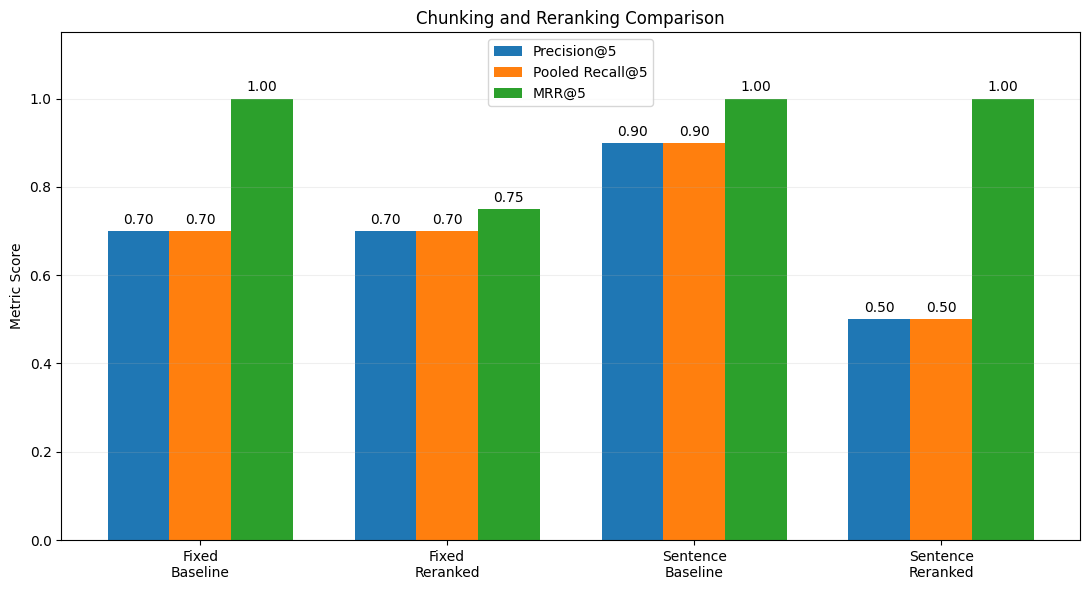

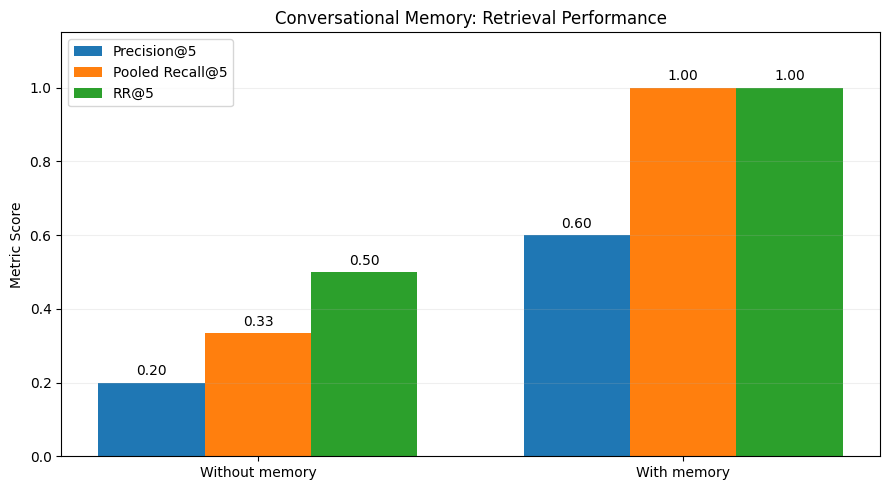


GENERATED FILES
------------------------------------------------------------
/content/rag_evaluation_charts/chunking_reranking_comparison.png
/content/rag_evaluation_charts/conversational_memory_comparison.png
/content/rag_evaluation_charts/evaluation_summary.csv

PASS: Evaluation charts generated successfully.


In [16]:

# ============================================================
# STEP 14: RETRIEVAL EVALUATION VISUALIZATIONS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

print("=" * 60)
print("STEP 14: RETRIEVAL EVALUATION CHARTS")
print("=" * 60)

OUTPUT_DIR = "/content/rag_evaluation_charts"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Compare baseline and reranking
summary = (
    evaluation_df[
        evaluation_df["Method"].isin(["Baseline", "Reranked"])
    ]
    .groupby(["Strategy", "Method"])[
        ["Precision@5", "Pooled Recall@5", "RR@5"]
    ]
    .mean()
)

configurations = [
    ("fixed", "Baseline"),
    ("fixed", "Reranked"),
    ("sentence", "Baseline"),
    ("sentence", "Reranked")
]

labels = [
    "Fixed\nBaseline",
    "Fixed\nReranked",
    "Sentence\nBaseline",
    "Sentence\nReranked"
]

metrics = [
    "Precision@5",
    "Pooled Recall@5",
    "RR@5"
]

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(configurations))
width = 0.25

for i, metric in enumerate(metrics):
    values = [
        summary.loc[config, metric]
        for config in configurations
    ]

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label="MRR@5" if metric == "RR@5" else metric
    )

    ax.bar_label(bars, fmt="%.2f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Metric Score")
ax.set_title("Chunking and Reranking Comparison")
ax.set_ylim(0, 1.15)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

CHART1 = f"{OUTPUT_DIR}/chunking_reranking_comparison.png"
plt.savefig(CHART1, dpi=200)
plt.show()

# 2. Compare conversational memory
memory_df = evaluation_df[
    evaluation_df["Query"] == "Q3"
].copy()

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(memory_df))
width = 0.25

for i, metric in enumerate(metrics):
    values = memory_df[metric].to_numpy()

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label="RR@5" if metric == "RR@5" else metric
    )

    ax.bar_label(bars, fmt="%.2f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(memory_df["Method"])
ax.set_ylabel("Metric Score")
ax.set_title("Conversational Memory: Retrieval Performance")
ax.set_ylim(0, 1.15)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

CHART2 = f"{OUTPUT_DIR}/conversational_memory_comparison.png"
plt.savefig(CHART2, dpi=200)
plt.show()

# 3. Save summary table
summary_table = summary.reset_index()
SUMMARY_PATH = f"{OUTPUT_DIR}/evaluation_summary.csv"
summary_table.to_csv(SUMMARY_PATH, index=False)

# 4. Verification
assert os.path.exists(CHART1)
assert os.path.exists(CHART2)
assert os.path.exists(SUMMARY_PATH)

print("\nGENERATED FILES")
print("-" * 60)
print(CHART1)
print(CHART2)
print(SUMMARY_PATH)

print("\n" + "=" * 60)
print("PASS: Evaluation charts generated successfully.")
print("=" * 60)


In [17]:

# ============================================================
# STEP 15: RELEVANCE LABEL AUDIT
# ============================================================

import pandas as pd

print("=" * 60)
print("STEP 15: RELEVANCE LABEL AUDIT")
print("=" * 60)

LABEL_PATH = "/content/arxiv_relevance_judgments_labeled.csv"
audit_df = pd.read_csv(LABEL_PATH)

# 1. Identify labels requiring review
review_items = [
    ("Q1", "fixed", "DOC_001_FIX_0017"),
    ("Q1", "sentence", "DOC_001_SENT_0021"),
    ("Q2", "fixed", "DOC_001_FIX_0000"),
    ("Q2", "fixed", "DOC_001_FIX_0002"),
    ("Q2", "fixed", "DOC_001_FIX_0011"),
    ("Q2", "fixed", "DOC_001_FIX_0035"),
    ("Q2", "sentence", "DOC_001_SENT_0000"),
    ("Q2", "sentence", "DOC_001_SENT_0004"),
    ("Q2", "sentence", "DOC_001_SENT_0012"),
    ("Q2", "sentence", "DOC_001_SENT_0032"),
    ("Q2", "sentence", "DOC_001_SENT_0043")
]

print(f"Total labels       : {len(audit_df)}")
print(f"Labels to review   : {len(review_items)}")

# 2. Display each label and its evidence
for number, (qid, strategy, cid) in enumerate(
    review_items, start=1
):
    matched = audit_df[
        (audit_df["query_id"] == qid) &
        (audit_df["strategy"] == strategy) &
        (audit_df["chunk_id"] == cid)
    ]

    if matched.empty:
        print(f"\nWARNING: Missing {qid} / {cid}")
        continue

    row = matched.iloc[0]

    print("\n" + "=" * 70)
    print(f"REVIEW {number}/{len(review_items)}")
    print(f"Question      : {row['query']}")
    print(f"Strategy      : {strategy}")
    print(f"Chunk ID      : {cid}")
    print(f"Current label : {int(row['relevance'])}")
    print("-" * 70)
    print(row["text"])
    print("=" * 70)

# 3. Verification
assert len(audit_df) == 38
assert audit_df["relevance"].notna().all()

print("\n" + "=" * 60)
print("PASS: Relevance audit candidates displayed.")
print("No labels were changed.")
print("=" * 60)


STEP 15: RELEVANCE LABEL AUDIT
Total labels       : 38
Labels to review   : 11

REVIEW 1/11
Question      : What are the advantages of additive models in statistical learning?
Strategy      : fixed
Chunk ID      : DOC_001_FIX_0017
Current label : 0
----------------------------------------------------------------------
@ xmath150 ^ s $ ] of the euclidean space @ xmath151 with regularity index @ xmath152 has the following asymptotic behavior with @ xmath153 : @ xmath154 here the power @ xmath155 depends linearly on the dimension @ xmath148. similar dimension - dependent bounds for the covering numbers of the rkhss associated with gaussian rbf - kernels can be found in @ xcite. the special bound in theorem [ capacitythm ] demonstrates an advantage of the additive model in terms of capacity of the additive hypothesis space. the third condition for our learning rates is about the noise level in the measure @ xmath6 with respect to the hypothesis space. before stating the general condition, 

In [18]:

# ============================================================
# STEP 16: APPLY AUDITED LABELS AND RECALCULATE METRICS
# ============================================================

import pandas as pd

print("=" * 60)
print("STEP 16: FINAL RELEVANCE CORRECTIONS")
print("=" * 60)

LABEL_PATH = "/content/arxiv_relevance_judgments_labeled.csv"

judgments_df = pd.read_csv(LABEL_PATH)

# 1. Apply audited corrections
corrections = {
    ("Q1", "fixed", "DOC_001_FIX_0017"): 1,
    ("Q1", "sentence", "DOC_001_SENT_0021"): 1,
    ("Q2", "fixed", "DOC_001_FIX_0000"): 0,
    ("Q2", "fixed", "DOC_001_FIX_0002"): 1,
    ("Q2", "fixed", "DOC_001_FIX_0011"): 0,
    ("Q2", "fixed", "DOC_001_FIX_0035"): 1,
    ("Q2", "sentence", "DOC_001_SENT_0004"): 0,
    ("Q2", "sentence", "DOC_001_SENT_0032"): 1
}

changes = 0

for (qid, strategy, cid), value in corrections.items():

    mask = (
        (judgments_df["query_id"] == qid) &
        (judgments_df["strategy"] == strategy) &
        (judgments_df["chunk_id"] == cid)
    )

    assert mask.sum() == 1, f"Missing chunk: {cid}"

    old_value = int(judgments_df.loc[mask, "relevance"].iloc[0])

    if old_value != value:
        changes += 1

    judgments_df.loc[mask, "relevance"] = value

judgments_df["relevance"] = judgments_df["relevance"].astype(int)

judgments_df.to_csv(LABEL_PATH, index=False)

# 2. Rebuild relevance lookup used by Step 13
relevance_lookup = {
    (row["query_id"], row["strategy"], row["chunk_id"]):
    int(row["relevance"])
    for _, row in judgments_df.iterrows()
}

# 3. Recalculate retrieval metrics
evaluation_rows = []

for query_id, query in enumerate(queries, start=1):

    for strategy in ["fixed", "sentence"]:

        for method, results in [
            ("Baseline", baseline_results[(query_id, strategy)]),
            ("Reranked", reranked_results[(query_id, strategy)])
        ]:

            metrics = evaluate_results(
                f"Q{query_id}", strategy, results
            )

            evaluation_rows.append({
                "Query": f"Q{query_id}",
                "Strategy": strategy,
                "Method": method,
                **metrics
            })

for method, results in [
    ("Without memory", memory_results["without_memory"]),
    ("With memory", memory_results["with_memory"])
]:

    metrics = evaluate_results("Q3", "sentence", results)

    evaluation_rows.append({
        "Query": "Q3",
        "Strategy": "sentence",
        "Method": method,
        **metrics
    })

evaluation_df = pd.DataFrame(evaluation_rows)

# 4. Display final metrics
print(f"\nLabels changed: {changes}")

print("\nFINAL RETRIEVAL METRICS")
print("-" * 60)
print(evaluation_df.to_string(index=False))

# 5. Summary
summary_df = (
    evaluation_df[
        evaluation_df["Method"].isin(["Baseline", "Reranked"])
    ]
    .groupby(["Strategy", "Method"])[
        ["Precision@5", "Pooled Recall@5", "RR@5"]
    ]
    .mean()
    .round(4)
    .reset_index()
)

print("\nFINAL CHUNKING AND RERANKING COMPARISON")
print("-" * 60)
print(summary_df.to_string(index=False))

# 6. Save final metrics
RESULTS_PATH = "/content/arxiv_retrieval_metrics.csv"
evaluation_df.to_csv(RESULTS_PATH, index=False)

assert len(evaluation_df) == 10
assert judgments_df["relevance"].notna().all()

print("\n" + "=" * 60)
print("PASS: Audited metrics recalculated successfully.")
print("=" * 60)


STEP 16: FINAL RELEVANCE CORRECTIONS

Labels changed: 8

FINAL RETRIEVAL METRICS
------------------------------------------------------------
Query Strategy         Method  Precision@5  Pooled Recall@5  RR@5
   Q1    fixed       Baseline          1.0           0.8333   1.0
   Q1    fixed       Reranked          0.8           0.6667   1.0
   Q1 sentence       Baseline          1.0           0.8333   1.0
   Q1 sentence       Reranked          0.8           0.6667   1.0
   Q2    fixed       Baseline          0.8           0.8000   1.0
   Q2    fixed       Reranked          0.6           0.6000   1.0
   Q2 sentence       Baseline          0.6           0.6000   1.0
   Q2 sentence       Reranked          0.6           0.6000   1.0
   Q3 sentence Without memory          0.2           0.3333   0.5
   Q3 sentence    With memory          0.6           1.0000   1.0

FINAL CHUNKING AND RERANKING COMPARISON
------------------------------------------------------------
Strategy   Method  Precision@5

STEP 17: FINAL EVALUATION VISUALIZATIONS


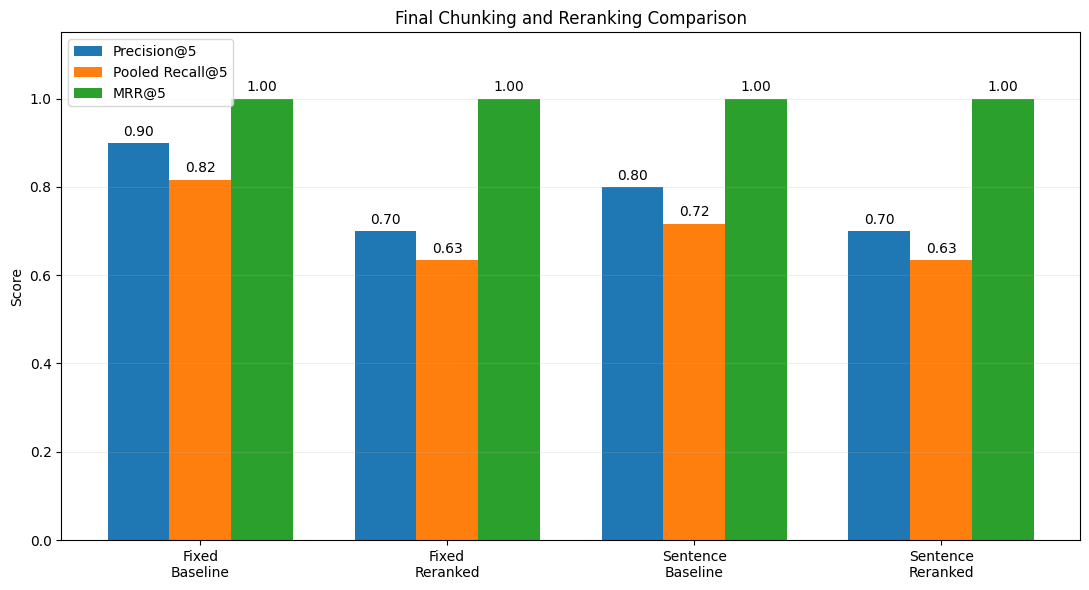

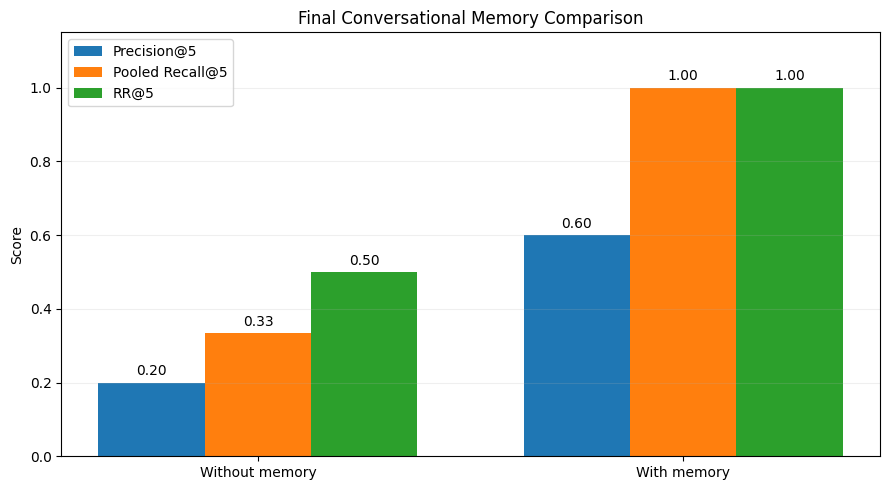


FINAL OUTPUT FILES
------------------------------------------------------------
/content/rag_evaluation_charts/chunking_reranking_comparison.png
/content/rag_evaluation_charts/conversational_memory_comparison.png
/content/rag_evaluation_charts/evaluation_summary.csv

PASS: Final evaluation charts regenerated.


In [19]:

# ============================================================
# STEP 17: REGENERATE FINAL EVALUATION CHARTS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

print("=" * 60)
print("STEP 17: FINAL EVALUATION VISUALIZATIONS")
print("=" * 60)

OUTPUT_DIR = "/content/rag_evaluation_charts"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Use corrected Step 16 metrics
final_df = evaluation_df.copy()

configurations = [
    ("fixed", "Baseline"),
    ("fixed", "Reranked"),
    ("sentence", "Baseline"),
    ("sentence", "Reranked")
]

labels = [
    "Fixed\nBaseline",
    "Fixed\nReranked",
    "Sentence\nBaseline",
    "Sentence\nReranked"
]

metrics = ["Precision@5", "Pooled Recall@5", "RR@5"]

summary = (
    final_df[final_df["Query"].isin(["Q1", "Q2"])]
    .groupby(["Strategy", "Method"])[metrics]
    .mean()
)

# 2. Chunking and reranking chart
fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(configurations))
width = 0.25

for i, metric in enumerate(metrics):

    values = [
        summary.loc[config, metric]
        for config in configurations
    ]

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label="MRR@5" if metric == "RR@5" else metric
    )

    ax.bar_label(bars, fmt="%.2f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Score")
ax.set_title("Final Chunking and Reranking Comparison")
ax.set_ylim(0, 1.15)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

CHART1 = f"{OUTPUT_DIR}/chunking_reranking_comparison.png"
plt.savefig(CHART1, dpi=200)
plt.show()

# 3. Conversational memory chart
memory_df = final_df[final_df["Query"] == "Q3"]

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(memory_df))

for i, metric in enumerate(metrics):

    bars = ax.bar(
        x + (i - 1) * width,
        memory_df[metric].to_numpy(),
        width,
        label="RR@5" if metric == "RR@5" else metric
    )

    ax.bar_label(bars, fmt="%.2f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(memory_df["Method"])
ax.set_ylabel("Score")
ax.set_title("Final Conversational Memory Comparison")
ax.set_ylim(0, 1.15)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

CHART2 = f"{OUTPUT_DIR}/conversational_memory_comparison.png"
plt.savefig(CHART2, dpi=200)
plt.show()

# 4. Save corrected summary
SUMMARY_PATH = f"{OUTPUT_DIR}/evaluation_summary.csv"

summary.reset_index().to_csv(
    SUMMARY_PATH,
    index=False
)

# 5. Verification
assert os.path.exists(CHART1)
assert os.path.exists(CHART2)
assert os.path.exists(SUMMARY_PATH)

print("\nFINAL OUTPUT FILES")
print("-" * 60)
print(CHART1)
print(CHART2)
print(SUMMARY_PATH)

print("\n" + "=" * 60)
print("PASS: Final evaluation charts regenerated.")
print("=" * 60)


In [20]:

# ============================================================
# STEP 18: GENERATE FINAL EXPERIMENTAL REPORT
# ============================================================

import pandas as pd
import os
from IPython.display import display, Markdown

print("=" * 60)
print("STEP 18: FINAL EXPERIMENTAL REPORT")
print("=" * 60)

REPORT_PATH = "/content/rag_evaluation_charts/final_report.md"

# 1. Extract final evaluation results
df = evaluation_df.copy()

baseline = df[
    (df["Method"] == "Baseline") &
    (df["Query"].isin(["Q1", "Q2"]))
]

reranked = df[
    (df["Method"] == "Reranked") &
    (df["Query"].isin(["Q1", "Q2"]))
]

without_memory = df[
    df["Method"] == "Without memory"
].iloc[0]

with_memory = df[
    df["Method"] == "With memory"
].iloc[0]

summary = (
    df[df["Query"].isin(["Q1", "Q2"])]
    .groupby(["Strategy", "Method"])[
        ["Precision@5", "Pooled Recall@5", "RR@5"]
    ]
    .mean()
)

# 2. Calculate comparisons
fixed_base = summary.loc[("fixed", "Baseline")]
sentence_base = summary.loc[("sentence", "Baseline")]

fixed_rerank = summary.loc[("fixed", "Reranked")]
sentence_rerank = summary.loc[("sentence", "Reranked")]

baseline_p = baseline["Precision@5"].mean()
reranked_p = reranked["Precision@5"].mean()

# 3. Generate report
report = f"""
# Improving RAG with Reranking, Chunking, and Conversational Memory

## 1. Objective

This experiment evaluates how chunking strategies, cross-encoder
reranking, and conversational memory affect retrieval quality
in a Retrieval-Augmented Generation (RAG) pipeline.

## 2. Dataset and Setup

- Dataset: ccdv/arxiv-summarization
- Dataset configuration: document
- Documents: 100 research papers
- Embedding model: sentence-transformers/all-MiniLM-L6-v2
- Vector database: ChromaDB
- Similarity metric: Cosine distance
- Reranker: cross-encoder/ms-marco-MiniLM-L-6-v2
- Chunk size: 240 tokens
- Chunk overlap: 40 tokens
- Initial retrieval candidates for reranking: 10
- Final retrieval results: Top 5

### Chunking Statistics

- Fixed-size chunks: 5,131
- Sentence-aware chunks: 5,811

## 3. Chunking Comparison

Fixed-size baseline Precision@5:
{fixed_base['Precision@5']:.4f}

Sentence-aware baseline Precision@5:
{sentence_base['Precision@5']:.4f}

Fixed-size baseline retrieval performed better on average
for the two evaluation queries.

The result suggests that sentence-aware chunking does not
automatically improve retrieval accuracy. Its effectiveness
depends on how relevant information is distributed across
sentence boundaries and chunk sizes.

## 4. Cross-Encoder Reranking

Average baseline Precision@5:
{baseline_p:.4f}

Average reranked Precision@5:
{reranked_p:.4f}

The cross-encoder changed the ranking of retrieved chunks,
but it did not consistently improve relevance.

For fixed-size chunks, Precision@5 changed from
{fixed_base['Precision@5']:.4f} to
{fixed_rerank['Precision@5']:.4f}.

For sentence-aware chunks, Precision@5 changed from
{sentence_base['Precision@5']:.4f} to
{sentence_rerank['Precision@5']:.4f}.

This demonstrates that reranking performance depends on
candidate quality, the reranking model, and query relevance.

## 5. Conversational Memory

Follow-up question:
"How do they handle high-dimensional data?"

Without memory, the question contains an ambiguous reference.

With memory, the query was rewritten as:
"How do additive models in statistical learning handle
high-dimensional data?"

Without memory Precision@5:
{without_memory['Precision@5']:.4f}

With memory Precision@5:
{with_memory['Precision@5']:.4f}

Without memory reciprocal rank:
{without_memory['RR@5']:.4f}

With memory reciprocal rank:
{with_memory['RR@5']:.4f}

Conversational memory improved retrieval by resolving
the ambiguous reference to additive models.

## 6. Evaluation Metrics

Precision@5 measures the proportion of relevant chunks
among the five retrieved results.

Pooled Recall@5 measures the proportion of relevant chunks
retrieved from the judged candidate pool, rather than
all relevant chunks in the entire corpus.

Reciprocal Rank@5 measures how early the first relevant
chunk appears.

Mean Reciprocal Rank (MRR@5) averages reciprocal ranks
across evaluation queries.

## 7. Limitations

1. Only 100 research papers were indexed.
2. Two initial queries and one follow-up were evaluated.
3. Relevance judgments were manually assigned and audited.
4. Pooled Recall@5 is not exhaustive corpus-level recall.
5. Mathematical expressions in the dataset contain
   placeholders such as @xmath and @xcite.
6. Cross-encoder performance may depend on the candidate
   retrieval depth and domain-specific relevance.
7. The experiment evaluates retrieval quality, not the
   factual correctness of generated RAG answers.

## 8. Conclusion

The experiment shows that retrieval improvements are
not guaranteed by adding more complex components.

Fixed-size baseline retrieval achieved the highest
average Precision@5 in this evaluation.

Cross-encoder reranking changed rankings but reduced
average Precision@5.

Conversational memory improved retrieval for an ambiguous
follow-up query by preserving the previous topic.

These findings are illustrative and require larger-scale
evaluation before generalization.
"""

# 4. Save report
with open(REPORT_PATH, "w", encoding="utf-8") as f:
    f.write(report)

# 5. Display report
display(Markdown(report))

# 6. Verification
assert os.path.exists(REPORT_PATH)
assert os.path.getsize(REPORT_PATH) > 1000

print("\n" + "=" * 60)
print("PASS: Final experimental report generated.")
print(f"Report saved: {REPORT_PATH}")
print("=" * 60)


STEP 18: FINAL EXPERIMENTAL REPORT



# Improving RAG with Reranking, Chunking, and Conversational Memory

## 1. Objective

This experiment evaluates how chunking strategies, cross-encoder
reranking, and conversational memory affect retrieval quality
in a Retrieval-Augmented Generation (RAG) pipeline.

## 2. Dataset and Setup

- Dataset: ccdv/arxiv-summarization
- Dataset configuration: document
- Documents: 100 research papers
- Embedding model: sentence-transformers/all-MiniLM-L6-v2
- Vector database: ChromaDB
- Similarity metric: Cosine distance
- Reranker: cross-encoder/ms-marco-MiniLM-L-6-v2
- Chunk size: 240 tokens
- Chunk overlap: 40 tokens
- Initial retrieval candidates for reranking: 10
- Final retrieval results: Top 5

### Chunking Statistics

- Fixed-size chunks: 5,131
- Sentence-aware chunks: 5,811

## 3. Chunking Comparison

Fixed-size baseline Precision@5:
0.9000

Sentence-aware baseline Precision@5:
0.8000

Fixed-size baseline retrieval performed better on average
for the two evaluation queries.

The result suggests that sentence-aware chunking does not
automatically improve retrieval accuracy. Its effectiveness
depends on how relevant information is distributed across
sentence boundaries and chunk sizes.

## 4. Cross-Encoder Reranking

Average baseline Precision@5:
0.8500

Average reranked Precision@5:
0.7000

The cross-encoder changed the ranking of retrieved chunks,
but it did not consistently improve relevance.

For fixed-size chunks, Precision@5 changed from
0.9000 to
0.7000.

For sentence-aware chunks, Precision@5 changed from
0.8000 to
0.7000.

This demonstrates that reranking performance depends on
candidate quality, the reranking model, and query relevance.

## 5. Conversational Memory

Follow-up question:
"How do they handle high-dimensional data?"

Without memory, the question contains an ambiguous reference.

With memory, the query was rewritten as:
"How do additive models in statistical learning handle
high-dimensional data?"

Without memory Precision@5:
0.2000

With memory Precision@5:
0.6000

Without memory reciprocal rank:
0.5000

With memory reciprocal rank:
1.0000

Conversational memory improved retrieval by resolving
the ambiguous reference to additive models.

## 6. Evaluation Metrics

Precision@5 measures the proportion of relevant chunks
among the five retrieved results.

Pooled Recall@5 measures the proportion of relevant chunks
retrieved from the judged candidate pool, rather than
all relevant chunks in the entire corpus.

Reciprocal Rank@5 measures how early the first relevant
chunk appears.

Mean Reciprocal Rank (MRR@5) averages reciprocal ranks
across evaluation queries.

## 7. Limitations

1. Only 100 research papers were indexed.
2. Two initial queries and one follow-up were evaluated.
3. Relevance judgments were manually assigned and audited.
4. Pooled Recall@5 is not exhaustive corpus-level recall.
5. Mathematical expressions in the dataset contain
   placeholders such as @xmath and @xcite.
6. Cross-encoder performance may depend on the candidate
   retrieval depth and domain-specific relevance.
7. The experiment evaluates retrieval quality, not the
   factual correctness of generated RAG answers.

## 8. Conclusion

The experiment shows that retrieval improvements are
not guaranteed by adding more complex components.

Fixed-size baseline retrieval achieved the highest
average Precision@5 in this evaluation.

Cross-encoder reranking changed rankings but reduced
average Precision@5.

Conversational memory improved retrieval for an ambiguous
follow-up query by preserving the previous topic.

These findings are illustrative and require larger-scale
evaluation before generalization.



PASS: Final experimental report generated.
Report saved: /content/rag_evaluation_charts/final_report.md


In [21]:

# ============================================================
# STEP 19: FINAL SUBMISSION VERIFICATION
# ============================================================

import os
import pandas as pd

print("=" * 60)
print("STEP 19: FINAL SUBMISSION VERIFICATION")
print("=" * 60)

required_files = {
    "Relevance labels":
        "/content/arxiv_relevance_judgments_labeled.csv",
    "Retrieval metrics":
        "/content/arxiv_retrieval_metrics.csv",
    "Chunking and reranking chart":
        "/content/rag_evaluation_charts/chunking_reranking_comparison.png",
    "Conversational memory chart":
        "/content/rag_evaluation_charts/conversational_memory_comparison.png",
    "Evaluation summary":
        "/content/rag_evaluation_charts/evaluation_summary.csv",
    "Experimental report":
        "/content/rag_evaluation_charts/final_report.md"
}

all_passed = True

print("\nFILE VERIFICATION")
print("-" * 60)

for name, path in required_files.items():
    exists = os.path.isfile(path)
    nonempty = exists and os.path.getsize(path) > 0
    status = "PASS" if nonempty else "FAIL"

    print(f"{status:5} | {name}")

    if not nonempty:
        all_passed = False

print("\nEVALUATION VERIFICATION")
print("-" * 60)

labels = pd.read_csv(
    "/content/arxiv_relevance_judgments_labeled.csv"
)
metrics = pd.read_csv(
    "/content/arxiv_retrieval_metrics.csv"
)

checks = {
    "38 relevance judgments": len(labels) == 38,
    "No missing labels": labels["relevance"].notna().all(),
    "10 evaluation rows": len(metrics) == 10,
    "Precision within range":
        metrics["Precision@5"].between(0, 1).all(),
    "Recall within range":
        metrics["Pooled Recall@5"].between(0, 1).all(),
    "Reciprocal rank within range":
        metrics["RR@5"].between(0, 1).all()
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL':5} | {name}")
    all_passed &= bool(passed)

print("\n" + "=" * 60)
if all_passed:
    print("PASS: All checked deliverables verified.")
else:
    print("FAIL: Some deliverables need attention.")
print("=" * 60)


STEP 19: FINAL SUBMISSION VERIFICATION

FILE VERIFICATION
------------------------------------------------------------
PASS  | Relevance labels
PASS  | Retrieval metrics
PASS  | Chunking and reranking chart
PASS  | Conversational memory chart
PASS  | Evaluation summary
PASS  | Experimental report

EVALUATION VERIFICATION
------------------------------------------------------------
PASS  | 38 relevance judgments
PASS  | No missing labels
PASS  | 10 evaluation rows
PASS  | Precision within range
PASS  | Recall within range
PASS  | Reciprocal rank within range

PASS: All checked deliverables verified.
